<a href="https://colab.research.google.com/github/Keplerzhao/keplerzhao/blob/master/LPPLS_Model_Confidence_multi_processing_23_Nov_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
%pip install -q --no-cache-dir \
    gudhi \
    POT \
    yfinance \
    curl_cffi \
    lmfit

In [18]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from scipy.stats import t as student_t
import requests

# ============================================================
# 1. EXCF Bubble Detector
# ============================================================

class EXCFExponentialDetector:
    def __init__(self, window=100, alpha=0.05, min_obs=10):
        self.window, self.alpha, self.min_obs = window, alpha, min_obs

    def detect_bubbles(self, prices):
        rows = []
        for i in range(len(prices) - self.min_obs + 1):
            w = prices.iloc[i:i+self.window]
            if len(w) < self.min_obs: continue
            p0 = w.iloc[0]; x, y = w.values[:-1]-p0, w.values[1:]-p0
            if np.var(x) == 0: continue
            fit = sm.OLS(y, x).fit()
            omega, se = float(fit.params[0]), float(fit.bse[0])
            p = 2*student_t.sf(abs((omega-1)/se), fit.df_resid) if se > 0 else np.nan
            den = np.sum((y-y.mean())**2)
            r2 = 1-np.sum((y-omega*x)**2)/den if den > 0 else np.nan
            bubble = np.isfinite(p) and np.isfinite(r2) and omega > 1 and p < self.alpha and r2 > 0.3
            rows.append(dict(start=w.index[0], end=w.index[-1], omega1=omega, p_val=p,
                             r_squared=r2, P0=p0, is_bubble=bubble,
                             quality="excellent" if bubble and r2>0.8 else "good" if bubble and r2>0.6 else "acceptable" if bubble else "poor"))
        return pd.DataFrame(rows)

# ============================================================
# 2. Exponential Curve Fit
# ============================================================

def fit_excf_exponential(prices, omega, p0):
    y = prices.to_numpy(dtype=float); t = np.arange(len(y))
    if omega <= 0 or not np.isfinite(omega): return np.full(len(y), np.nan), np.nan
    with np.errstate(over="ignore", invalid="ignore"): basis = omega**t
    den = np.dot(basis, basis)
    if not np.isfinite(den) or den <= 0: return np.full(len(y), np.nan), np.nan
    A = np.dot(basis, y-p0)/den
    curve = p0+A*basis
    ss = np.sum((y-y.mean())**2)
    r2 = 1-np.sum((y-curve)**2)/ss if ss > 0 else np.nan
    return curve, r2

# ============================================================
# 3. Best Fit Selection (Overlap Filtering)
# ============================================================

def select_best_excf_fits(prices, signals, overlap=0.6, max_fits=8, min_r2=0.3):
    candidates = []
    for _, s in signals[signals.is_bubble].iterrows():
        w = prices.loc[s.start:s.end]
        curve, r2 = fit_excf_exponential(w, s.omega1, s.P0)
        if not np.isfinite(r2) or r2 < min_r2: continue
        candidates.append(dict(start=s.start, end=s.end, dates=w.index, curve=curve, omega=s.omega1, r2=r2))
    candidates.sort(key=lambda z: z["r2"], reverse=True)
    selected = []
    for c in candidates:
        if any(len(c["dates"].intersection(z["dates"]))/min(len(c["dates"]),len(z["dates"])) >= overlap for z in selected): continue
        selected.append(c)
        if max_fits is not None and len(selected) >= max_fits: break
    return sorted(selected, key=lambda z: z["start"])

# ============================================================
# 4. Plot: Same Bubble Shading for Panel 1 & Panel 3
# ============================================================

def plot_excf_exponential_analysis(prices, signals, title="EXCF Bubble Analysis",
                                   log_price=False, overlap=0.6, max_fits=8, min_r2=0.3):
    px = prices.astype(float)
    yp = np.log(px.where(px > 0)) if log_price else px
    ylabel = "Log Price" if log_price else "Price"
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 11), sharex=True,
                                          gridspec_kw={"height_ratios":[2,1,2.5]})
    bubbles = signals[signals.is_bubble]

    for ax in (ax1, ax3):
        ax.plot(yp.index, yp, color="navy", lw=1.5, label="Price series", zorder=2)

    # Merge ALL detected bubble windows
    intervals = sorted(zip(bubbles.start, bubbles.end))
    merged = []
    for a, b in intervals:
        if merged and a <= merged[-1][1]:
            merged[-1] = (merged[-1][0], max(b, merged[-1][1]))
        else:
            merged.append((a, b))

    # Panel 1: Price + ALL bubble periods
    for j, (a, b) in enumerate(merged):
        ax1.axvspan(a, b, color="lightblue", alpha=0.3, zorder=0,
                    label="Bubble period" if j == 0 else None)
    ax1.set_title(title+" - Detection"); ax1.set_ylabel(ylabel); ax1.legend()

    # Panel 2: Omega parameter
    omega = signals.groupby("end")["omega1"].last().reindex(px.index).interpolate(limit_area="inside")
    ax2.plot(omega.index, omega, color="green", lw=1.5)
    ax2.axhline(1, color="red", ls="--", label="ω₁ = 1")
    ax2.set_title("EXCF Growth Parameter"); ax2.set_ylabel("ω₁"); ax2.legend()

    # Panel 3: Same bubble shading + BEST fitted curves only
    for a, b in merged:
        ax3.axvspan(a, b, color="lightblue", alpha=0.3, zorder=0)

    selected = select_best_excf_fits(px, signals, overlap, max_fits, min_r2)
    colors = plt.cm.tab10(np.linspace(0, 1, max(len(selected), 1)))

    for i, f in enumerate(selected):
        curve = np.log(np.where(f["curve"] > 0, f["curve"], np.nan)) if log_price else f["curve"]
        ax3.plot(f["dates"], curve, color=colors[i], lw=2.5, zorder=3,
                 label=f'{f["start"]:%Y-%m} (ω₁={f["omega"]:.3f}, R²={f["r2"]:.3f})')

    ax3.set_title("Best EXCF Fits (Overlap Filtered)"); ax3.set_ylabel(ylabel); ax3.set_xlabel("Date")
    ax3.legend(bbox_to_anchor=(1.02,1), loc="upper left", fontsize=9)

    for ax in (ax1, ax2, ax3):
        ax.grid(alpha=0.3)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax3.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

    print(f"Bubble windows: {len(bubbles)} | Bubble periods: {len(merged)} | Selected fits: {len(selected)}")
    return selected

# ============================================================
# 5. FMP Download + EXCF
# ============================================================

def excf_from_symbol(sym, start, end, api_key, *, window=100, alpha=0.05, min_obs=10,
                     week_rule="W-FRI", log_price=False, show_info=True,
                     overlap=0.6, max_fits=8, min_r2=0.3):

    url = f"https://financialmodelingprep.com/api/v3/historical-price-full/{sym.upper()}"
    r = requests.get(url, params={"from":start, "to":end, "serietype":"line", "apikey":api_key}, timeout=20)
    r.raise_for_status()
    data = r.json().get("historical", [])
    if not data: raise ValueError("FMP returned no data. Check API key, ticker and endpoint.")

    daily = pd.DataFrame(data).assign(date=lambda d: pd.to_datetime(d.date)).set_index("date").sort_index()
    weekly = daily.loc[start:end, "close"].astype(float).resample(week_rule).last().dropna()
    if len(weekly) < min_obs: raise ValueError("Insufficient price observations.")
    if show_info: print(f"{sym.upper()}: {weekly.index[0].date()} → {weekly.index[-1].date()} | n={len(weekly)}")

    signals = EXCFExponentialDetector(window, alpha, min_obs).detect_bubbles(weekly)
    selected = plot_excf_exponential_analysis(weekly, signals, f"{sym.upper()} EXCF Analysis",
                                               log_price, overlap, max_fits, min_r2)

    if show_info and not signals.empty:
        b = signals[signals.is_bubble]
        print(f"Detected: {len(b)}/{len(signals)} | Displayed: {len(selected)}")
        if len(b): print(f"Avg ω₁: {b.omega1.mean():.4f} | Avg regression R²: {b.r_squared.mean():.4f}")
    return signals

# ============================================================
# 6. Example
# ============================================================

# signals = excf_from_symbol(
#     "NVDA", "2018-01-01", "2026-11-20", api_key,
#     window=100, overlap=0.6, max_fits=8, min_r2=0.3
# )


In [19]:
# -*- coding: utf-8 -*-
# GSADF (PSY 2015) — fast BSADF + fast Monte Carlo date-stamping CV
# ADF regression is identical to the original: no intercept, k=int(1.5*n**(1/3))

import requests, pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import math, warnings
from numba import njit
from datetime import datetime
warnings.filterwarnings('ignore')
today = datetime.today().date()

API_KEY = "490ed0ef6adef36a548539c3e6da425e" # 用你原来的 API_KEY 替换
CV_SIMS, CV_EVERY, CV_SEED = 80, 40, 42  # 快速: 80次模拟，每40个交易日校准一次

# --- 1. 用一次累计矩阵替代每个窗口重复创建 OLS 设计矩阵 ---
@njit
def _cross_prefix(y):
    T = len(y)
    maxlag = int(1.5 * T ** (1/3)) + 1
    p = maxlag + 2
    S = np.zeros((T + 1, p, p))
    z = np.zeros(p)
    for t in range(T):
        z[:] = 0.0
        z[0] = y[t]
        for j in range(1, maxlag + 1):
            if t >= j:
                z[j] = y[t-j+1] - y[t-j]
        if t < T - 1:
            z[-1] = y[t+1] - y[t]
        for i in range(p):
            for j in range(p):
                S[t+1, i, j] = S[t, i, j] + z[i] * z[j]
    return S

@njit
def _adf_fast(S, r1, r2):
    n = r2-r1+1
    k = int(1.5 * n ** (1/3))
    rows = n-1-k
    p = k+1
    if rows <= p or p >= S.shape[1]:
        return -1e9
    low, high, target = r1+k, r2, S.shape[1]-1
    xx = np.empty((p, p)); xy = np.empty(p)
    for i in range(p):
        xy[i] = S[high,i,target] - S[low,i,target]
        for j in range(p):
            xx[i,j] = S[high,i,j] - S[low,i,j]
    yy = S[high,target,target] - S[low,target,target]
    try:
        beta = np.linalg.solve(xx, xy)
        e0 = np.zeros(p); e0[0] = 1.0
        inv00 = np.linalg.solve(xx, e0)[0]
    except:
        return -1e9
    var = ((yy - np.dot(beta, xy)) / (rows - p)) * inv00
    if var <= 0 or not np.isfinite(var):
        return -1e9
    return beta[0] / math.sqrt(var)

@njit
def rolling_bsadf_numba(logp, min_win):
    T = len(logp)
    bsadf = np.full(T, np.nan)
    S = _cross_prefix(logp)
    for r2 in range(min_win, T):
        sup_t = -1e9
        for r1 in range(0, r2-min_win+1):  # 和原始版本一样：每个起点都计算
            v = _adf_fast(S, r1, r2)
            if v > sup_t: sup_t = v
        bsadf[r2] = sup_t
    return bsadf

@njit
def _cv_simulated_paths(paths, min_win, endpoints):
    B = paths.shape[0]
    out = np.empty((B, len(endpoints)))
    for b in range(B):
        S = _cross_prefix(paths[b])
        for j in range(len(endpoints)):
            r2 = endpoints[j]
            mx = -1e9
            for r1 in range(0, r2-min_win+1):  # CV 与观察 BSADF 完全同规格
                v = _adf_fast(S, r1, r2)
                if v > mx: mx = v
            out[b,j] = mx
    return out

# --- 2. 蒙特卡洛仅稀疏计算 CV；不会减少真实 BSADF 的起点搜索 ---
def cv_sequence_95(logp, min_win, sims=CV_SIMS, every=CV_EVERY, seed=CV_SEED):
    T = len(logp)
    cv = np.full(T, np.nan)
    if T <= min_win: return cv
    # 使用首个可检测窗口的数据校准无截距零假设；不读取后续实际价格
    sigma = float(np.std(np.diff(logp[:min_win+1]), ddof=1))
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError('初始价格变化不足，无法模拟 CV')
    endpoints = np.arange(min_win, T, every, dtype=np.int64)
    paths = np.empty((sims, T), dtype=np.float64)
    for b in range(sims):
        rng = np.random.default_rng(seed + b)
        paths[b,0] = logp[0]
        paths[b,1:] = logp[0] + np.cumsum(rng.normal(0, sigma, T-1))
    simulated = _cv_simulated_paths(paths, min_win, endpoints)
    q = np.quantile(simulated, .95, axis=0)
    # 前向保持而不是用未来日期插值，避免已有历史 CV 随新增数据重绘
    for j, r2 in enumerate(endpoints):
        next_r2 = endpoints[j+1] if j+1 < len(endpoints) else T
        cv[r2:next_r2] = q[j]
    return cv

# --- 3. 主函数：与原来的数据读取、阴影、绘图保持一致 ---
def run_gsadf(symbol='601288.SS', start='2022-01-01', end='2026-11-22'):
    url = (f'https://financialmodelingprep.com/api/v3/historical-price-full/'
           f'{symbol}?from={start}&to={end}&serietype=line&apikey={API_KEY}')
    response = requests.get(url, timeout=15)
    response.raise_for_status()
    js = response.json().get('historical', [])
    if not js:
        raise ValueError(f'❌ API 无返回，请检查 symbol {symbol} 或 API key。')

    daily = (pd.DataFrame(js)
             .assign(date=lambda d: pd.to_datetime(d['date']))
             .set_index('date').sort_index())
    price = daily['close'].dropna().astype(float)
    if price.empty or (price <= 0).any():
        raise ValueError('价格为空或包含非正价格，不能计算 log')
    logp, dates, T = np.log(price.values), price.index, len(price)

    r0_formula = 0.01 + 1.8 / np.sqrt(T)
    MIN_WIN = math.ceil(r0_formula * T)
    print(f'Sample T={T}, r0={r0_formula:.4f}, MIN_WIN={MIN_WIN}')

    bsadf = rolling_bsadf_numba(logp, MIN_WIN)
    cv95_seq = cv_sequence_95(logp, MIN_WIN)
    gsadf = np.nanmax(bsadf)
    bflag = bsadf > cv95_seq
    print(f'{symbol}: GSADF={gsadf:.3f} | Bubble Count={bflag.sum()}')

    bubble_periods, start_b = [], None
    for d, f in zip(dates, bflag):
        if f and start_b is None:
            start_b = d
        elif not f and start_b is not None:
            bubble_periods.append((start_b, d))
            start_b = None
    if start_b is not None:
        bubble_periods.append((start_b, dates[-1]))

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(12, 6), sharex=True,
        gridspec_kw={'height_ratios': [2.5, 1]})
    ax1.plot(dates, price, color='black')
    for s, e in bubble_periods:
        ax1.axvspan(s, e, color='gray', alpha=.3)
    ax1.set_title(f'{symbol} — (Data)')

    ax2.plot(dates, bsadf, color='purple', label='BSADF')
    ax2.plot(dates, cv95_seq, color='blue', ls='--', label='95% CV')
    for s, e in bubble_periods:
        ax2.axvspan(s, e, color='gray', alpha=.3)
    ax2.legend()
    ax2.xaxis.set_major_locator(mdates.YearLocator())
    ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.xticks(rotation=45)
    plt.tight_layout(); plt.show()
    return {'symbol': symbol, 'T': T, 'GSADF': gsadf, 'bubble_periods': bubble_periods}

# Example:
# results = run_gsadf('GLD', '2022-01-01', '2026-11-22')


In [20]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
import requests
from scipy.optimize import minimize
from multiprocessing import Pool, cpu_count
from tqdm.notebook import tqdm
from typing import List, Dict, Optional, Tuple
import warnings
warnings.filterwarnings("ignore")

# ============================================================
# 1. 数据获取
# ============================================================
def get_close_prices(symbol: str, start_date: str,
                     api_key: str = '490ed0ef6adef36a548539c3e6da425e') -> pd.DataFrame:
    today = datetime.today().date()
    url = f"https://financialmodelingprep.com/api/v3/historical-price-full/{symbol}"
    params = {'from': start_date, 'to': today, 'apikey': api_key}
    response = requests.get(url, params=params, timeout=30)
    if response.status_code != 200:
        raise Exception(f"Request failed: {response.status_code}")
    data = response.json().get("historical", [])
    if not data:
        raise ValueError("No data found.")
    df = pd.DataFrame([{'date': item['date'], 'close': item['close']} for item in data])
    df['date'] = pd.to_datetime(df['date'])
    df = df.sort_values('date').reset_index(drop=True)
    df['log_price'] = np.log(df['close'].astype(float))
    return df


# ============================================================
# 2. 核心 LPPL 函数
# ============================================================
def lppls_func(t, tc, m, w, a, b, c1, c2):
    dt = np.abs(tc - t) + 1e-8
    return a + np.power(dt, m) * (b + c1*np.cos(w*np.log(dt)) + c2*np.sin(w*np.log(dt)))


def matrix_equation(t, y, tc, m, w):
    dt = np.abs(tc - t) + 1e-8
    phase = np.log(dt)
    fi = np.power(dt, m)
    gi = fi * np.cos(w * phase)
    hi = fi * np.sin(w * phase)
    X = np.column_stack([np.ones(len(t)), fi, gi, hi])
    try:
        beta = np.linalg.lstsq(X, y, rcond=None)[0]
    except:
        beta = np.zeros(4)
    return beta


def compute_reliability(m, w, O, D, rel_err, b, tc, t2, dt) -> float:
    """
    论文启发的可靠性评分（0~1）
    综合参数合理性 + 拟合质量 + tc 位置
    分数越高，该拟合越值得信任
    """
    score = 1.0

    # 1. m 越靠近 0.3~0.7 越可靠
    if 0.3 <= m <= 0.7:
        score *= 1.0
    elif 0.2 <= m <= 0.8:
        score *= 0.7
    else:
        score *= 0.4

    # 2. ω 在经典区间更可靠
    if 6.5 <= w <= 11.5:
        score *= 1.0
    elif 6.0 <= w <= 13.0:
        score *= 0.75
    else:
        score *= 0.4

    # 3. O 和 D 越高越好
    score *= min(1.0, O / 4.0)
    score *= min(1.0, D / 1.2)

    # 4. 相对误差越小越好
    score *= max(0.1, 1.0 - rel_err * 12)

    # 5. |B| 不能太小
    score *= min(1.0, abs(b) / 0.05)

    # 6. tc 距离 t2 的位置（太近或太远都降分）
    tc_offset = (tc - t2) / dt
    if 0.0 <= tc_offset <= 0.06:
        score *= 1.0
    elif -0.03 <= tc_offset <= 0.10:
        score *= 0.7
    else:
        score *= 0.3

    return float(np.clip(score, 0.0, 1.0))


def fit_single_window(t: np.ndarray, y: np.ndarray, max_searches: int = 18) -> Optional[Dict]:
    t1, t2 = float(t[0]), float(t[-1])
    dt = t2 - t1
    if dt < 80:
        return None

    bounds = [
        (t2 - 0.20*dt, t2 + 0.10*dt),
        (0.15, 0.85),
        (6.0, 13.0)
    ]

    best = None
    best_loss = np.inf

    for _ in range(max_searches):
        seed = np.array([np.random.uniform(lo, hi) for lo, hi in bounds])

        def obj(x):
            tc, m, w = x
            try:
                a, b, c1, c2 = matrix_equation(t, y, tc, m, w)
                pred = lppls_func(t, tc, m, w, a, b, c1, c2)
                return np.mean((pred - y)**2)
            except:
                return 1e12

        try:
            res = minimize(obj, seed, method='L-BFGS-B', bounds=bounds,
                           options={'maxiter': 60, 'ftol': 1e-9})
            if not res.success:
                continue

            tc, m, w = res.x
            a, b, c1, c2 = matrix_equation(t, y, tc, m, w)
            c = np.sqrt(c1**2 + c2**2 + 1e-12)

            O = (w / (2 * np.pi)) * np.log((tc - t1) / max(tc - t2, 1e-6))
            D = (m * abs(b)) / (w * c + 1e-12)
            pred = lppls_func(t, tc, m, w, a, b, c1, c2)
            rel_err = np.mean(np.abs(y - pred) / (np.abs(pred) + 1e-8))

            # 基础过滤
            valid = (
                0.15 <= m <= 0.85 and
                6.0  <= w <= 13.0 and
                (t2 - 0.05*dt) <= tc <= (t2 + 0.08*dt) and
                O >= 2.5 and
                D >= 0.85 and
                rel_err <= 0.045 and
                abs(b) > 0.015
            )

            if valid and res.fun < best_loss:
                best_loss = res.fun
                reliability = compute_reliability(m, w, O, D, rel_err, b, tc, t2, dt)
                best = {
                    "tc": tc, "m": m, "w": w,
                    "a": a, "b": b, "c1": c1, "c2": c2, "c": c,
                    "O": O, "D": D, "rel_err": rel_err,
                    "reliability": reliability,
                    "is_positive": b < 0,
                    "is_negative": b > 0
                }
        except:
            continue
    return best


# ============================================================
# 3. 多核 Worker（返回更多信息）
# ============================================================
def _worker(args):
    t2_idx, t_full, y_full, window_sizes, max_searches = args
    t2 = t_full[t2_idx]

    pos_fits = []
    neg_fits = []
    total = 0

    for dt in window_sizes:
        t1 = t2 - dt
        if t1 < t_full[0]:
            continue
        mask = (t_full >= t1) & (t_full <= t2)
        t_win = t_full[mask]
        y_win = y_full[mask]
        if len(t_win) < 80:
            continue

        total += 1
        fit = fit_single_window(t_win, y_win, max_searches)
        if fit is not None:
            if fit["is_positive"]:
                pos_fits.append(fit)
            elif fit["is_negative"]:
                neg_fits.append(fit)

    # 原始 Confidence
    pos_conf = len(pos_fits) / total if total > 0 else 0.0
    neg_conf = len(neg_fits) / total if total > 0 else 0.0

    # 可靠性加权 Confidence（论文核心思想）
    pos_rel = np.mean([f["reliability"] for f in pos_fits]) if pos_fits else 0.0
    neg_rel = np.mean([f["reliability"] for f in neg_fits]) if neg_fits else 0.0

    pos_weighted = pos_conf * pos_rel
    neg_weighted = neg_conf * neg_rel

    # 平均 tc（用于 DTCAI）
    pos_tc = np.mean([f["tc"] for f in pos_fits]) if pos_fits else np.nan
    neg_tc = np.mean([f["tc"] for f in neg_fits]) if neg_fits else np.nan

    return {
        "t2_idx": t2_idx,
        "pos_conf": pos_conf,
        "neg_conf": neg_conf,
        "pos_rel": pos_rel,
        "neg_rel": neg_rel,
        "pos_weighted": pos_weighted,
        "neg_weighted": neg_weighted,
        "pos_tc": pos_tc,
        "neg_tc": neg_tc,
        "pos_valid": len(pos_fits),
        "neg_valid": len(neg_fits),
        "total": total
    }


def compute_indicators(dates, log_price, window_sizes=None, step=5,
                       max_searches=18, workers=None) -> pd.DataFrame:
    if window_sizes is None:
        window_sizes = list(range(250, 501, 15))
    if workers is None:
        workers = max(1, cpu_count() - 1)

    t = np.arange(len(log_price), dtype=np.float64)
    y = log_price.astype(np.float64)
    min_t2 = max(window_sizes) + 20
    t2_list = list(range(min_t2, len(t), step))

    print(f"多核计算中（含可靠性评分）...")
    print(f"时间点: {len(t2_list)} | 窗口数: {len(window_sizes)} | searches: {max_searches} | workers: {workers}")

    args = [(idx, t, y, window_sizes, max_searches) for idx in t2_list]

    with Pool(processes=workers) as pool:
        results = list(tqdm(pool.imap(_worker, args), total=len(args), desc="Computing"))

    records = []
    for r in results:
        idx = r["t2_idx"]
        # 简化 DTCAI：距离临界时间的天数（越小风险越高），再乘可靠性
        dtc_pos = (r["pos_tc"] - idx) if not np.isnan(r["pos_tc"]) else np.nan
        dtc_neg = (r["neg_tc"] - idx) if not np.isnan(r["neg_tc"]) else np.nan

        records.append({
            "date": dates.iloc[idx],
            "t2": idx,
            "pos_confidence": r["pos_conf"],
            "neg_confidence": r["neg_conf"],
            "pos_reliability": r["pos_rel"],
            "neg_reliability": r["neg_rel"],
            "pos_weighted": r["pos_weighted"],
            "neg_weighted": r["neg_weighted"],
            "pos_dtc": dtc_pos,
            "neg_dtc": dtc_neg,
            "pos_valid": r["pos_valid"],
            "neg_valid": r["neg_valid"],
            "total_fits": r["total"]
        })
    return pd.DataFrame(records)


# ============================================================
# 4. 可视化
# ============================================================
import matplotlib.dates as mdates

def plot_indicators(price_df, ind_df, title="LPPL with AI-inspired Reliability"):
    fig, ax1 = plt.subplots(figsize=(14, 5))

    ax1.plot(price_df['date'], price_df['log_price'],
             color='tab:blue', lw=1.2, label='Log Price')
    ax1.set_ylabel('Log Price', color='tab:blue')
    ax1.tick_params(axis='y', labelcolor='tab:blue')
    ax1.grid(True, alpha=0.3)

    ax2 = ax1.twinx()
    ax2.plot(ind_df['date'], ind_df['pos_weighted'],
             color='tab:red', lw=1.8, label='Pos Weighted Conf')
    ax2.plot(ind_df['date'], ind_df['neg_weighted'],
             color='tab:green', lw=1.8, label='Neg Weighted Conf')
    ax2.set_ylabel('Weighted Confidence (Conf × Reliability)')
    ax2.set_ylim(0, max(0.4, ind_df[['pos_weighted','neg_weighted']].max().max()*1.2))

    # 日期横轴
    ax1.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.setp(ax1.get_xticklabels(), rotation=45, ha='right')
    ax1.set_xlabel('Date')

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
    ax1.set_title(title)

    plt.tight_layout()
    plt.show()


# ============================================================
# 5. 主程序
# ============================================================


In [27]:

# -*- coding: utf-8 -*-
# Fractal Dimension — Katz / Higuchi | One-Function Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yfinance as yf
import warnings
warnings.filterwarnings("ignore")


def get_close_prices(symbol: str, start_date: str,
                     api_key: str = '490ed0ef6adef36a548539c3e6da425e') -> pd.DataFrame:
    today = datetime.today().date()
    url = f"https://financialmodelingprep.com/api/v3/historical-price-full/{symbol}"
    params = {'from': start_date, 'to': today, 'apikey': api_key}
    response = requests.get(url, params=params, timeout=30)
    if response.status_code != 200:
        raise Exception(f"Request failed: {response.status_code}")
    data = response.json().get("historical", [])
    if not data:
        raise ValueError("No data found.")
    df = pd.DataFrame([{'date': item['date'], 'close': item['close']} for item in data])
    df['date'] = pd.to_datetime(df['date'])
    df = df.sort_values('date').reset_index(drop=True)
    df['log_price'] = np.log(df['close'].astype(float))
    return df

def fd_from_symbol(symbol="GLD", start="2023-01-01", end=None,
                   window=40, threshold=1.25, method="Katz",
                   kmax=10, use_log=False, show_both=False):

    # ---------- 1. Katz FD ----------
    def katz_fd(x):
        x = np.asarray(x, dtype=float)
        n = len(x)
        if n < 3 or not np.all(np.isfinite(x)): return np.nan

        L = np.sum(np.abs(np.diff(x)))
        d = np.max(np.abs(x - x[0]))
        if L <= 0 or d <= 0: return np.nan

        den = np.log(n-1) + np.log(d/L)
        return np.log(n-1)/den if den > 0 else np.nan

    # ---------- 2. Higuchi FD ----------
    def higuchi_fd(x):
        x = np.asarray(x, dtype=float)
        n = len(x)
        if n < 10 or not np.all(np.isfinite(x)): return np.nan

        lengths, scales = [], []
        for k in range(1, min(kmax, (n-1)//2)+1):
            lm = []
            for m in range(k):
                idx = np.arange(m, n, k)
                steps = len(idx)-1
                if steps < 1: continue
                dist = np.abs(np.diff(x[idx])).sum()
                lm.append(dist*(n-1)/(steps*k*k))

            if lm and np.mean(lm) > 0:
                lengths.append(np.mean(lm))
                scales.append(k)

        if len(scales) < 3: return np.nan
        return -np.polyfit(np.log(scales), np.log(lengths), 1)[0]

    # ---------- 3. Download ----------
    method = method.capitalize()
    if method not in ("Katz", "Higuchi"):
        raise ValueError("method must be 'Katz' or 'Higuchi'")



    df = get_close_prices(symbol,start)
    price = df["Close"].squeeze().dropna().astype(float)
    if price.empty: raise ValueError("No price data downloaded.")
    if len(price) < window: raise ValueError("Insufficient observations.")

    series = np.log(price) if use_log else price

    # ---------- 4. Rolling FD ----------
    fd = series.rolling(window).apply(
        katz_fd if method == "Katz" else higuchi_fd, raw=True
    )

    if show_both:
        other = series.rolling(window).apply(
            higuchi_fd if method == "Katz" else katz_fd, raw=True
        )

    signal = (fd < threshold) & fd.notna()

    # ---------- 5. Statistics ----------
    # print(f"\n{'='*50}")
    # print(f"{symbol.upper()} — Fractal Dimension Analysis")
    # print(f"{'='*50}")
    # print(f"Method: {method} | Window: {window} | Threshold: {threshold}")
    # print(f"Observations: {len(price)}")
    # print("\nFD Statistics:")
    # print(fd.describe().round(3))
    # print(f"\nLatest Price: {price.iloc[-1]:,.2f}")
    # print(f"Latest FD: {fd.iloc[-1]:.3f}")
    # print("Status:", "LOW FD — Strong directional structure"
    #       if signal.iloc[-1] else "NORMAL FD")

    # ---------- 6. Plot ----------
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(15, 8), sharex=True,
        gridspec_kw={"height_ratios": [2, 1], "hspace": 0.06}
    )

    ax1.plot(price.index, price, color="steelblue", lw=1,
             label=f"{symbol.upper()} Price")
    ax1.set_title(f"{symbol.upper()} — Fractal Dimension ({method}, {window}-day)")
    ax1.set_ylabel("Price")
    ax1.legend(loc="upper left")

    ax2.plot(fd.index, fd, color="mediumpurple", lw=1,
             label=f"{window}-day Rolling FD ({method})")

    if show_both:
        ax2.plot(other.index, other, color="darkorange", lw=0.8,
                 alpha=0.8,
                 label="Higuchi FD" if method == "Katz" else "Katz FD")

    ax2.axhline(threshold, color="red", ls="--", lw=1,
                label=f"Threshold = {threshold}")
    ax2.set_ylabel("Fractal Dimension")
    ax2.set_xlabel("Date")
    ax2.legend(loc="upper left")

    # ---------- 7. Warning regions ----------
    for ax in (ax1, ax2):
        ax.fill_between(fd.index, 0, 1, where=signal.to_numpy(),
                        color="red", alpha=0.13,
                        transform=ax.get_xaxis_transform())
        ax.grid(alpha=0.2)

    ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.setp(ax2.get_xticklabels(), rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    # ---------- 8. Return results ----------
    return pd.DataFrame({
        "Price": price, "FD": fd, "Low_FD": signal
    })



FMP Stable: aapl | 2020-01-02 to 2026-11-20

Latest close (2026-11-20): $342.56
Next upper alert: $386.88
Next lower alert: $322.71


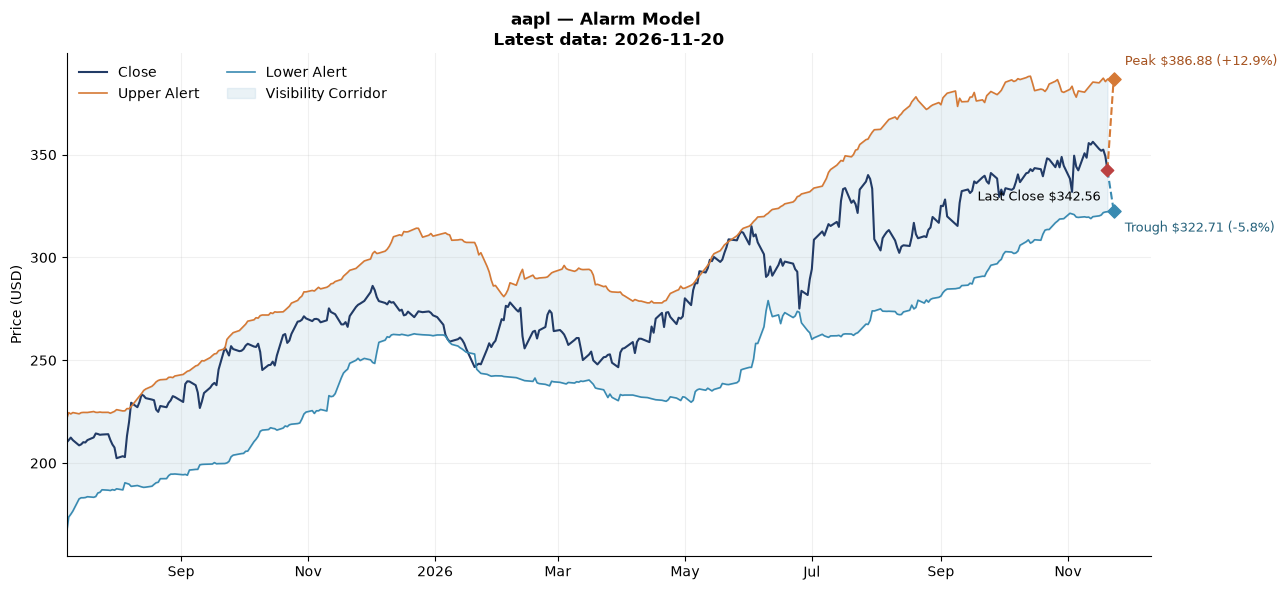

,date,close,upper,lower
0,2020-01-02,75.09,NaN,NaN
1,2020-01-03,74.36,NaN,NaN
2,2020-01-06,74.95,NaN,NaN
3,2020-01-07,74.60,NaN,NaN
4,2020-01-08,75.80,NaN,NaN
...,...,...,...,...
1727,2026-11-16,352.78,384.942274,320.234920
1728,2026-11-17,351.91,386.075871,320.646662
1729,2026-11-18,352.45,387.212806,321.831440
1730,2026-11-19,349.21,385.558986,322.124362


In [33]:

import os
from getpass import getpass
from datetime import datetime
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ================ SETTINGS ================
SYMBOL = "SOXX"
START_DATE = "2020-01-01"
WINDOW = 130
TARGET = 32
PLOT_DAYS = 500        # None = all history
MAX_MULTIPLE = 10.0
# ==========================================

def get_prices(symbol, start, api_key):
    end = datetime.now(
        ZoneInfo("America/New_York")
    ).date().isoformat()

    sources = [
        (
            "FMP Stable",
            "https://financialmodelingprep.com/stable/historical-price-eod/full",
            {"symbol":symbol, "from":start, "to":end, "apikey":api_key}
        ),
        (
            "FMP Legacy",
            f"https://financialmodelingprep.com/api/v3/historical-price-full/{symbol}",
            {"from":start, "to":end, "apikey":api_key}
        )
    ]

    errors = []
    for label, url, params in sources:
        try:
            r = requests.get(url, params=params, timeout=30)
            r.raise_for_status()
            payload = r.json()
            hist = payload if isinstance(payload, list) else payload.get("historical", [])

            if not isinstance(hist, list) or not hist:
                raise ValueError(f"Empty FMP response: {str(payload)[:150]}")

            df = pd.DataFrame(hist)
            df = df[["date", "close"]].copy()
            df["date"] = pd.to_datetime(df["date"], errors="coerce")
            df["close"] = pd.to_numeric(df["close"], errors="coerce")
            df = (df.dropna().query("close > 0")
                    .drop_duplicates("date", keep="last")
                    .sort_values("date").reset_index(drop=True))

            if len(df) < WINDOW + 2:
                raise ValueError("Insufficient price history")

            print(f"{label}: {symbol} | "
                  f"{df.date.iloc[0].date()} to "
                  f"{df.date.iloc[-1].date()}")
            return df

        except Exception as e:
            errors.append(f"{label}: {e}")

    raise RuntimeError("FMP download failed:\n" + "\n".join(errors))


# Exact Extreme-Visibility threshold
def visibility_thresholds(logs, base, window, target):
    n = len(logs)
    start = max(0, n - window)
    count = n - start

    if target < 1 or target > count:
        return np.nan, np.nan

    peak_limits = np.empty(count)
    trough_limits = np.empty(count)

    for pos, i in enumerate(range(start, n)):
        if i == n - 1:
            peak_limits[pos] = -np.inf
            trough_limits[pos] = np.inf
            continue

        k = np.arange(i + 1, n)
        limits = logs[i] + (
            (n - i) * (logs[k] - logs[i]) / (k - i)
        )

        peak_limits[pos] = limits.max()
        trough_limits[pos] = limits.min()

    peak_log = np.partition(
        peak_limits, target - 1
    )[target - 1]

    trough_log = np.partition(
        trough_limits, count - target
    )[count - target]

    upper = np.exp(max(np.log(base), peak_log))
    lower = np.exp(min(np.log(base), trough_log))

    if not np.isfinite(upper) or upper > base * MAX_MULTIPLE:
        upper = np.nan
    if not np.isfinite(lower) or lower < base / MAX_MULTIPLE:
        lower = np.nan

    return float(upper), float(lower)


def extreme_visibility_corridor(
    symbol=SYMBOL,
    start=START_DATE,
    window=WINDOW,
    target=TARGET,
    plot_days=PLOT_DAYS,
    api_key=None
):
    if window < 3 or not 1 <= target <= window:
        raise ValueError("Require window >= 3 and 1 <= target <= window")

    api_key = "490ed0ef6adef36a548539c3e6da425e"

    df = get_prices(symbol, start, api_key)

    closes = df["close"].to_numpy(dtype=float)
    logs = np.log(closes)
    n = len(df)

    upper = np.full(n, np.nan)
    lower = np.full(n, np.nan)

    # Historical next-day alerts, without look-ahead
    for j in range(window, n):
        upper[j], lower[j] = visibility_thresholds(
            logs[:j], closes[j - 1], window, target
        )

    df["upper"] = upper
    df["lower"] = lower

    # Calculate NEXT-session alert using ALL observed prices
    today_close = closes[-1]
    upper_nd, lower_nd = visibility_thresholds(
        logs, today_close, window, target
    )

    last_date = df["date"].iloc[-1]
    next_date = last_date + pd.offsets.BDay(1)

    print(f"\nLatest close ({last_date.date()}): ${today_close:.2f}")
    print(f"Next upper alert: ${upper_nd:.2f}")
    print(f"Next lower alert: ${lower_nd:.2f}")

    if plot_days is not None:
        cutoff = last_date - pd.Timedelta(days=plot_days)
        dfp = df[df["date"] >= cutoff]
    else:
        dfp = df

    dates = dfp["date"].to_numpy()
    price = dfp["close"].to_numpy(dtype=float)
    up = dfp["upper"].to_numpy(dtype=float)
    dn = dfp["lower"].to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(13, 6))

    ax.plot(dates, price, lw=1.5, color="#223b66", label="Close")
    ax.plot(dates, up, lw=1.2, color="#d57935", label="Upper Alert")
    ax.plot(dates, dn, lw=1.2, color="#398ab1", label="Lower Alert")

    ax.fill_between(
        dates, dn, up,
        where=np.isfinite(up) & np.isfinite(dn),
        color="#a8c9dd", alpha=0.24,
        label="Visibility Corridor"
    )

    # Next-day triangular fan
    if np.isfinite(upper_nd):
        ax.plot(
            [last_date, next_date],
            [today_close, upper_nd],
            "--", color="#d57935", lw=1.5
        )
        ax.scatter(next_date, upper_nd, marker="D",
                   color="#d57935", s=45, zorder=6)

        pct_up = (upper_nd / today_close - 1) * 100
        ax.annotate(
            f"Peak ${upper_nd:,.2f} ({pct_up:+.1f}%)",
            xy=(next_date, upper_nd),
            xytext=(8, 10),
            textcoords="offset points",
            fontsize=9, color="#a65320"
        )

    if np.isfinite(lower_nd):
        ax.plot(
            [last_date, next_date],
            [today_close, lower_nd],
            "--", color="#398ab1", lw=1.5
        )
        ax.scatter(next_date, lower_nd, marker="D",
                   color="#398ab1", s=45, zorder=6)

        pct_dn = (lower_nd / today_close - 1) * 100
        ax.annotate(
            f"Trough ${lower_nd:,.2f} ({pct_dn:+.1f}%)",
            xy=(next_date, lower_nd),
            xytext=(8, -15),
            textcoords="offset points",
            fontsize=9, color="#25617b"
        )

    ax.scatter(
        last_date, today_close,
        marker="D", color="#bb4141", s=40, zorder=7
    )
    ax.annotate(
        f"Last Close ${today_close:,.2f}",
        xy=(last_date, today_close),
        xytext=(-5, -22),
        textcoords="offset points",
        ha="right", fontsize=9
    )

    ax.set_title(
        f"{symbol} — Alarm Model \n"
        f"Latest data: {last_date.date()}",
        fontweight="bold"
    )
    ax.set_ylabel("Price (USD)")
    ax.set_xlim(dfp["date"].iloc[0], next_date + pd.Timedelta(days=18))
    ax.grid(alpha=0.18)
    ax.legend(loc="upper left", frameon=False, ncol=2)
    ax.spines[["top", "right"]].set_visible(False)

    locator = mdates.AutoDateLocator(minticks=5, maxticks=10)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    plt.tight_layout()
    plt.show()

    return df



SOXX: 2022-01-03 → 2026-11-20 | n=1227


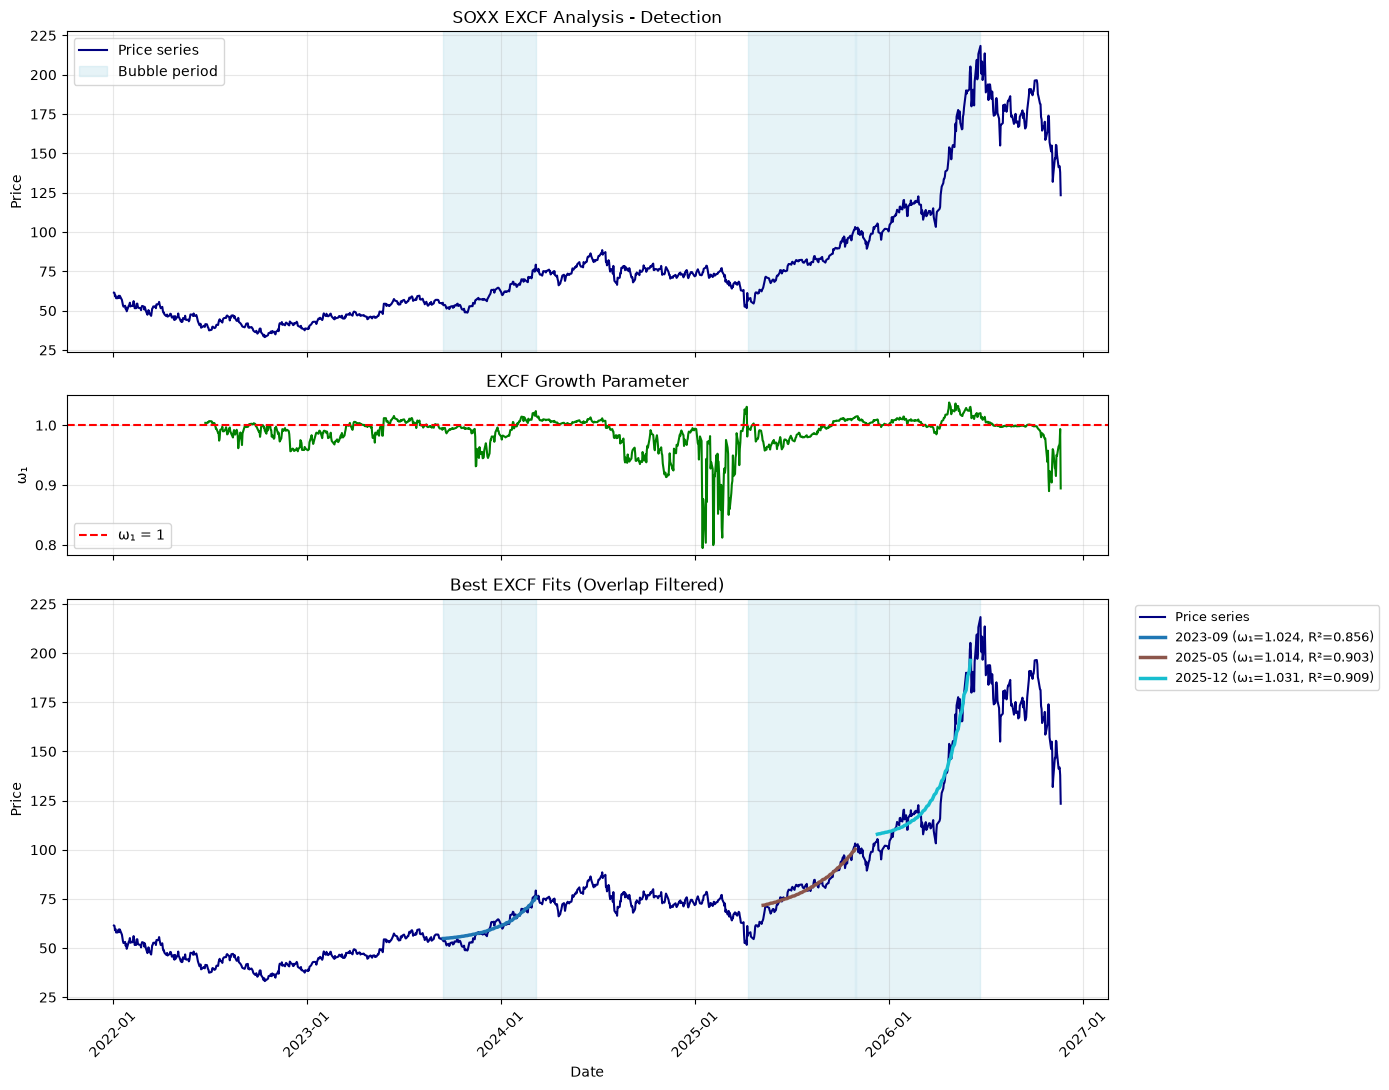

Bubble windows: 34 | Bubble periods: 3 | Selected fits: 3
Detected: 34/1216 | Displayed: 3
Avg ω₁: 1.0227 | Avg regression R²: 0.9776


KeyError: 'Close'

In [30]:
Portfolio=['SOXX']

for Symbol in Portfolio:
  signals = excf_from_symbol(Symbol, "2022-01-01", today,api_key="490ed0ef6adef36a548539c3e6da425e",
      window=120, alpha=0.05, min_obs=12, week_rule="D", log_price=False)
  signals[signals.is_bubble].tail()
  result = fd_from_symbol(Symbol, "2022-01-01", window=40)
  extreme_visibility_corridor(Symbol)
  run_gsadf(Symbol,"2022-01-01", today)
  # ================ RUN ================



In [7]:
if __name__ == "__main__":
    stock = "SOXX"
    start = "2022-01-01"

    print(f"获取 {stock} 数据...")
    df = get_close_prices(stock, start)
    print(f"数据长度: {len(df)} | {df['date'].iloc[0].date()} → {df['date'].iloc[-1].date()}")

    # ---------- 推荐配置（250-500，步长15） ----------
    window_sizes = list(range(250, 501, 15))
    step = 5
    max_searches = 15
    workers = max(1, cpu_count() - 1)
    # ------------------------------------------------

    ind_df = compute_indicators(
        dates=df['date'],
        log_price=df['log_price'].values,
        window_sizes=window_sizes,
        step=step,
        max_searches=max_searches,
        workers=workers
    )

    # 平滑
    for col in ['pos_confidence', 'neg_confidence', 'pos_weighted', 'neg_weighted',
                'pos_reliability', 'neg_reliability']:
        ind_df[col] = ind_df[col].rolling(window=5, min_periods=1, center=True).mean()

    plot_indicators(df, ind_df, title=f"{stock} - LPPL with AI-inspired Reliability")

    ind_df.to_csv(f"{stock}_lppls_reliability.csv", index=False)
    print("结果已保存（含加权Confidence + 可靠性）")

获取 SOXX 数据...
数据长度: 1227 | 2022-01-03 → 2026-11-20
多核计算中（含可靠性评分）...
时间点: 144 | 窗口数: 17 | searches: 15 | workers: 1


Computing:   0%|          | 0/144 [00:00<?, ?it/s]

KeyboardInterrupt: 

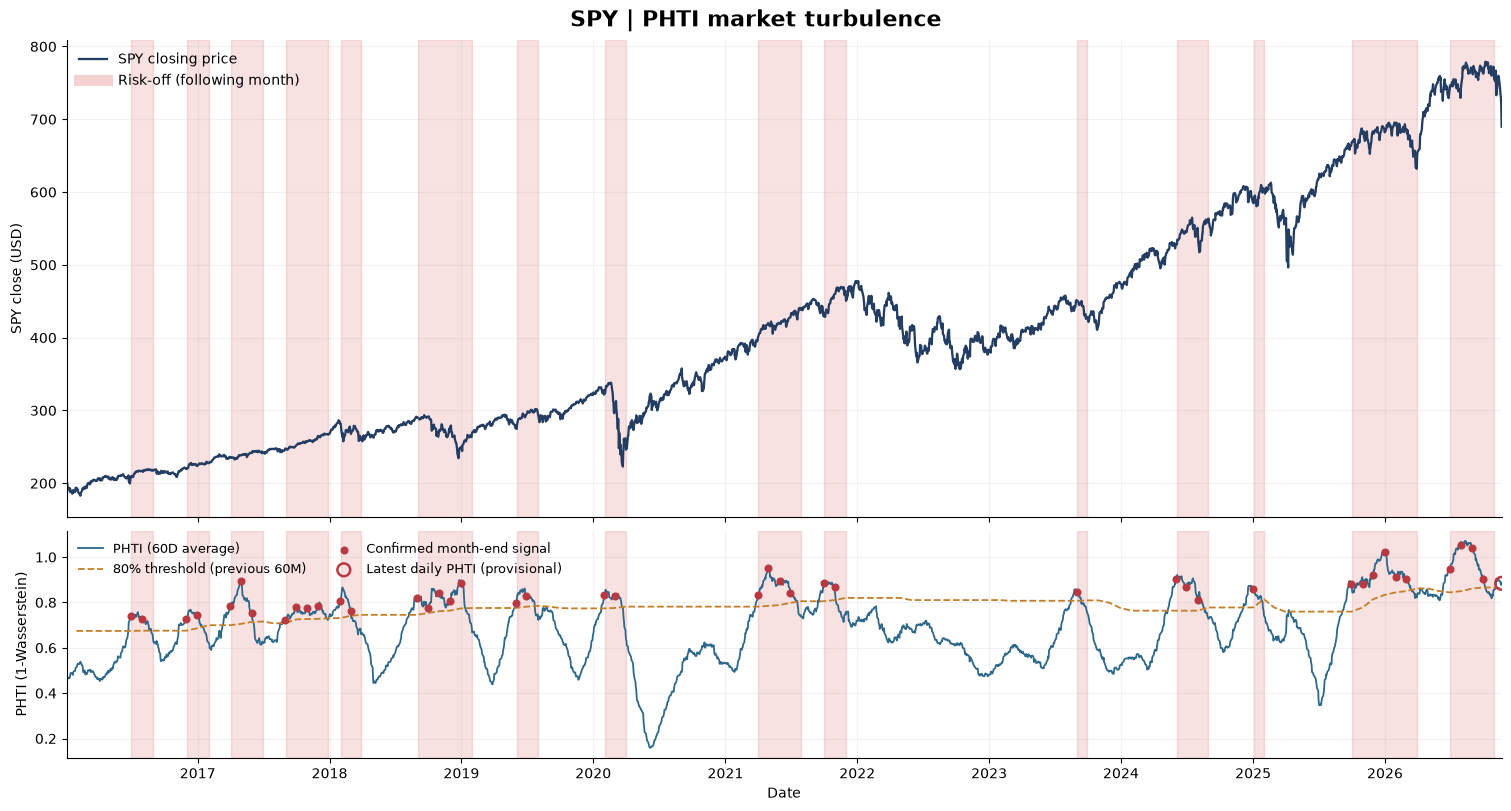

In [32]:
# -*- coding: utf-8 -*-
"""PHTI for Colab — Financial Modeling Prep EOD, charts only (no CSV/PNG writes).

Colab install cell:
    %pip -q install gudhi POT numpy pandas scipy scikit-learn matplotlib requests

Model: 9 sector ETFs, 60-day H1 persistence, day-to-day Wasserstein-1,
60-day smoothing, previous 60 completed months' 80th percentile threshold.
Red shadow: following month of confirmed month-end risk-off signal.
Hollow circle: current unfinished month's LIVE PHTI (not confirmed).
Prices: FMP daily unadjusted 'close', requested through today's New York date.
"""
import os, time, getpass, warnings
from datetime import datetime
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
import gudhi as gd
from gudhi.wasserstein import wasserstein_distance

warnings.filterwarnings('ignore', category=FutureWarning)

# ---------- SETTINGS ----------
SECTORS = ['XLB','XLE','XLF','XLI','XLK','XLP','XLU','XLV','XLY']
HISTORY_START = '2010-01-01'    # warm-up for a 2016+ chart
PLOT_START = '2016-01-01'
WINDOW, SMOOTH = 60, 60
Q_MONTHS, MIN_Q_MONTHS, Q_LEVEL = 60, 36, 0.80
EMPTY_RULE = 'original'        # Keep earlier PHTI convention when H1 diagram empty
# ------------------------------


def fmp_close(symbol, key, start, end, session):
    """Use user's FMP v3 API; if unavailable, try FMP stable EOD API."""
    endpoints = [
        (f'https://financialmodelingprep.com/api/v3/historical-price-full/{symbol}',
         {'from': start, 'to': end, 'apikey': key}),
        ('https://financialmodelingprep.com/stable/historical-price-eod/full',
         {'symbol': symbol, 'from': start, 'to': end, 'apikey': key}),
    ]
    errors = []
    for url, params in endpoints:
        try:
            for retry in range(3):
                r = session.get(url, params=params, timeout=40)
                if r.status_code in (429, 500, 502, 503, 504) and retry < 2:
                    time.sleep(2 ** retry)
                    continue
                break
            if not r.ok:
                raise RuntimeError(f'HTTP {r.status_code}: {r.text[:120]}')
            body = r.json()
            records = body.get('historical', []) if isinstance(body, dict) else body
            if not isinstance(records, list) or not records:
                raise ValueError('empty or unsupported API response')
            df = pd.DataFrame(records)
            if not {'date', 'close'}.issubset(df.columns):
                raise ValueError('date/close missing in response')
            df['date'] = pd.to_datetime(df['date'], errors='coerce')
            df['close'] = pd.to_numeric(df['close'], errors='coerce')
            df = df.dropna(subset=['date', 'close'])
            df = df.loc[df['close'] > 0].drop_duplicates('date', keep='last')
            s = df.set_index('date')['close'].sort_index().loc[start:end].rename(symbol)
            if len(s) < 300:
                raise ValueError(f'not enough historical records: {len(s)}')
            return s
        except (requests.RequestException, ValueError, RuntimeError) as exc:
            errors.append(f'{url.split("/")[3]}: {str(exc)[:90]}')
    raise RuntimeError(f'FMP download failed for {symbol}: ' + ' | '.join(errors))


def get_prices():
    api_key = '490ed0ef6adef36a548539c3e6da425e'
    if not api_key:
        raise ValueError('Enter your FMP API key.')
    end = datetime.now(ZoneInfo('America/New_York')).date().isoformat()
    with requests.Session() as session:
        session.headers.update({'User-Agent': 'PHTI-Research/1.0'})
        data = {sym: fmp_close(sym, api_key, HISTORY_START, end, session)
                for sym in ['SPY'] + SECTORS}
    all_px = pd.concat(data.values(), axis=1).sort_index()
    # Keep SPY at its latest available EOD; do NOT truncate it to a stale sector.
    spy = all_px['SPY'].dropna()
    industry_prices = all_px[SECTORS].dropna(how='any')
    # The model uses only days with all 9 sectors AND SPY present.
    industry_prices = industry_prices.loc[industry_prices.index.intersection(spy.index)]
    if len(industry_prices) < 1000:
        raise ValueError('Not enough dates shared by SPY and all nine sector ETFs.')
    returns = industry_prices.pct_change(fill_method=None).dropna()
    last_by_ticker = {symbol: series.index[-1].date() for symbol, series in data.items()}
    return spy, returns, last_by_ticker, end


def diagram(window_returns):
    pts = StandardScaler().fit_transform(np.asarray(window_returns, dtype=float))
    ds = pdist(pts)
    if len(ds) == 0 or not np.isfinite(ds).all() or ds.max() <= 0:
        return np.empty((0, 2))
    edge = float(ds.max() * 1.5)
    st = gd.RipsComplex(points=pts, max_edge_length=edge).create_simplex_tree(max_dimension=2)
    pairs = [[b, d] for dim, (b, d) in st.persistence()
             if dim == 1 and np.isfinite(d) and d-b > 1e-8 and d < edge*0.99]
    return np.asarray(pairs, dtype=float).reshape(-1, 2)


def wd(a, b):
    if EMPTY_RULE == 'original' and (len(a)==0 or len(b)==0):
        return 0.0
    if len(a)==0 and len(b)==0:
        return 0.0
    if len(a)==0:
        return float(np.sum((b[:,1]-b[:,0]) / np.sqrt(2)))
    if len(b)==0:
        return float(np.sum((a[:,1]-a[:,0]) / np.sqrt(2)))
    return float(wasserstein_distance(a, b, order=1, internal_p=2,
                                      keep_essential_parts=False))


def calculate_phti(returns):
    values, dates = returns.to_numpy(dtype=float), returns.index
    if len(dates) < WINDOW + SMOOTH:
        raise ValueError('Not enough sector data for rolling windows.')
    prev = diagram(values[:WINDOW])
    out = [0.0]
    for i in range(WINDOW, len(dates)):
        current = diagram(values[i-WINDOW+1:i+1])
        out.append(wd(current, prev))
        prev = current
    raw = pd.Series(out, index=dates[WINDOW-1:], name='PHTI_raw')
    return raw.rolling(SMOOTH, min_periods=SMOOTH//2).mean().rename('PHTI_60D')


def signals(smoothed, spy_index):
    daily = smoothed.dropna()
    m = daily.groupby(daily.index.to_period('M')).last()
    this_month = pd.Period(datetime.now(ZoneInfo('America/New_York')).strftime('%Y-%m'), freq='M')
    confirmed = m.loc[m.index < this_month]
    threshold = confirmed.shift(1).rolling(Q_MONTHS, min_periods=MIN_Q_MONTHS).quantile(Q_LEVEL)
    flags = (confirmed > threshold) & threshold.notna()
    shadow = pd.Series(flags.reindex(spy_index.to_period('M')-1).fillna(False).to_numpy(bool),
                       index=spy_index)
    live = daily.iloc[-1]
    live_date = daily.index[-1]
    live_threshold = confirmed.tail(Q_MONTHS).quantile(Q_LEVEL) if len(confirmed)>=MIN_Q_MONTHS else np.nan
    return confirmed, threshold, flags, shadow, live, live_date, live_threshold


def plot(spy, smoothed, confirmed, thresh, flags, shadow, live, live_date, live_threshold,
         last_dates, request_end):
    p = spy.loc[PLOT_START:]
    s = smoothed.loc[PLOT_START:]
    sh = shadow.reindex(p.index).fillna(False)
    th = thresh.copy()
    th.index = th.index.to_timestamp('M')
    th = th.loc[PLOT_START:]
    if np.isfinite(live_threshold) and len(th) and live_date > th.index[-1]:
        th.loc[live_date] = live_threshold
    dots = confirmed[flags].copy()
    dots.index = dots.index.to_timestamp('M')
    dots = dots.loc[PLOT_START:]

    fig, (a,b) = plt.subplots(2, 1, sharex=True, figsize=(15, 8),
                              gridspec_kw={'height_ratios':[2.1,1]}, layout='constrained')
    fig.suptitle('SPY | PHTI market turbulence', fontsize=16, fontweight='bold')
    a.plot(p.index, p.values, lw=1.65, color='#243e63', label='SPY closing price')
    for ax in (a,b):
        ax.fill_between(p.index,0,1,where=sh.to_numpy(bool),step='post',
                        transform=ax.get_xaxis_transform(),color='#d96a69',alpha=.20,zorder=0)
        ax.grid(alpha=.16)
        ax.spines[['top','right']].set_visible(False)
    a.plot([],[],lw=8,color='#d96a69',alpha=.30,label='Risk-off (following month)')
    a.set_ylabel('SPY close (USD)'); a.legend(frameon=False,loc='upper left')
    b.plot(s.index,s.values,color='#2e688b',lw=1.3,label='PHTI (60D average)')
    b.plot(th.index,th.values,'--',color='#c47e27',lw=1.3,label='80% threshold (previous 60M)')
    b.scatter(dots.index,dots.values,color='#b83941',s=23,zorder=5,label='Confirmed month-end signal')
    # A hollow dot at latest daily reading, even if the current month is unfinished.
    b.scatter([live_date],[live],s=85,facecolors='none',edgecolors='#b83941',
              linewidths=1.8,zorder=6,label='Latest daily PHTI (provisional)')
    b.set_ylabel('PHTI (1-Wasserstein)'); b.set_xlabel('Date')
    b.legend(loc='upper left',frameon=False,fontsize=9,ncol=2)
    b.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5,maxticks=12))
    b.xaxis.set_major_formatter(mdates.ConciseDateFormatter(b.xaxis.get_major_locator()))
    a.set_xlim(p.index[0],p.index[-1])

    plt.show()
    plt.close(fig)


def main():
    spy, rets, last, end = get_prices()  # fresh FMP data every run, no cache files
    smooth = calculate_phti(rets)
    c,t,f,shadow,live,live_date,lt = signals(smooth,spy.index)
    plot(spy,smooth,c,t,f,shadow,live,live_date,lt,last,end)
    return spy, smooth     # in-memory objects only, no saved CSV or PNG


if __name__ == '__main__':
    spy, phti = main()


LIT: 1227 observations | Stable


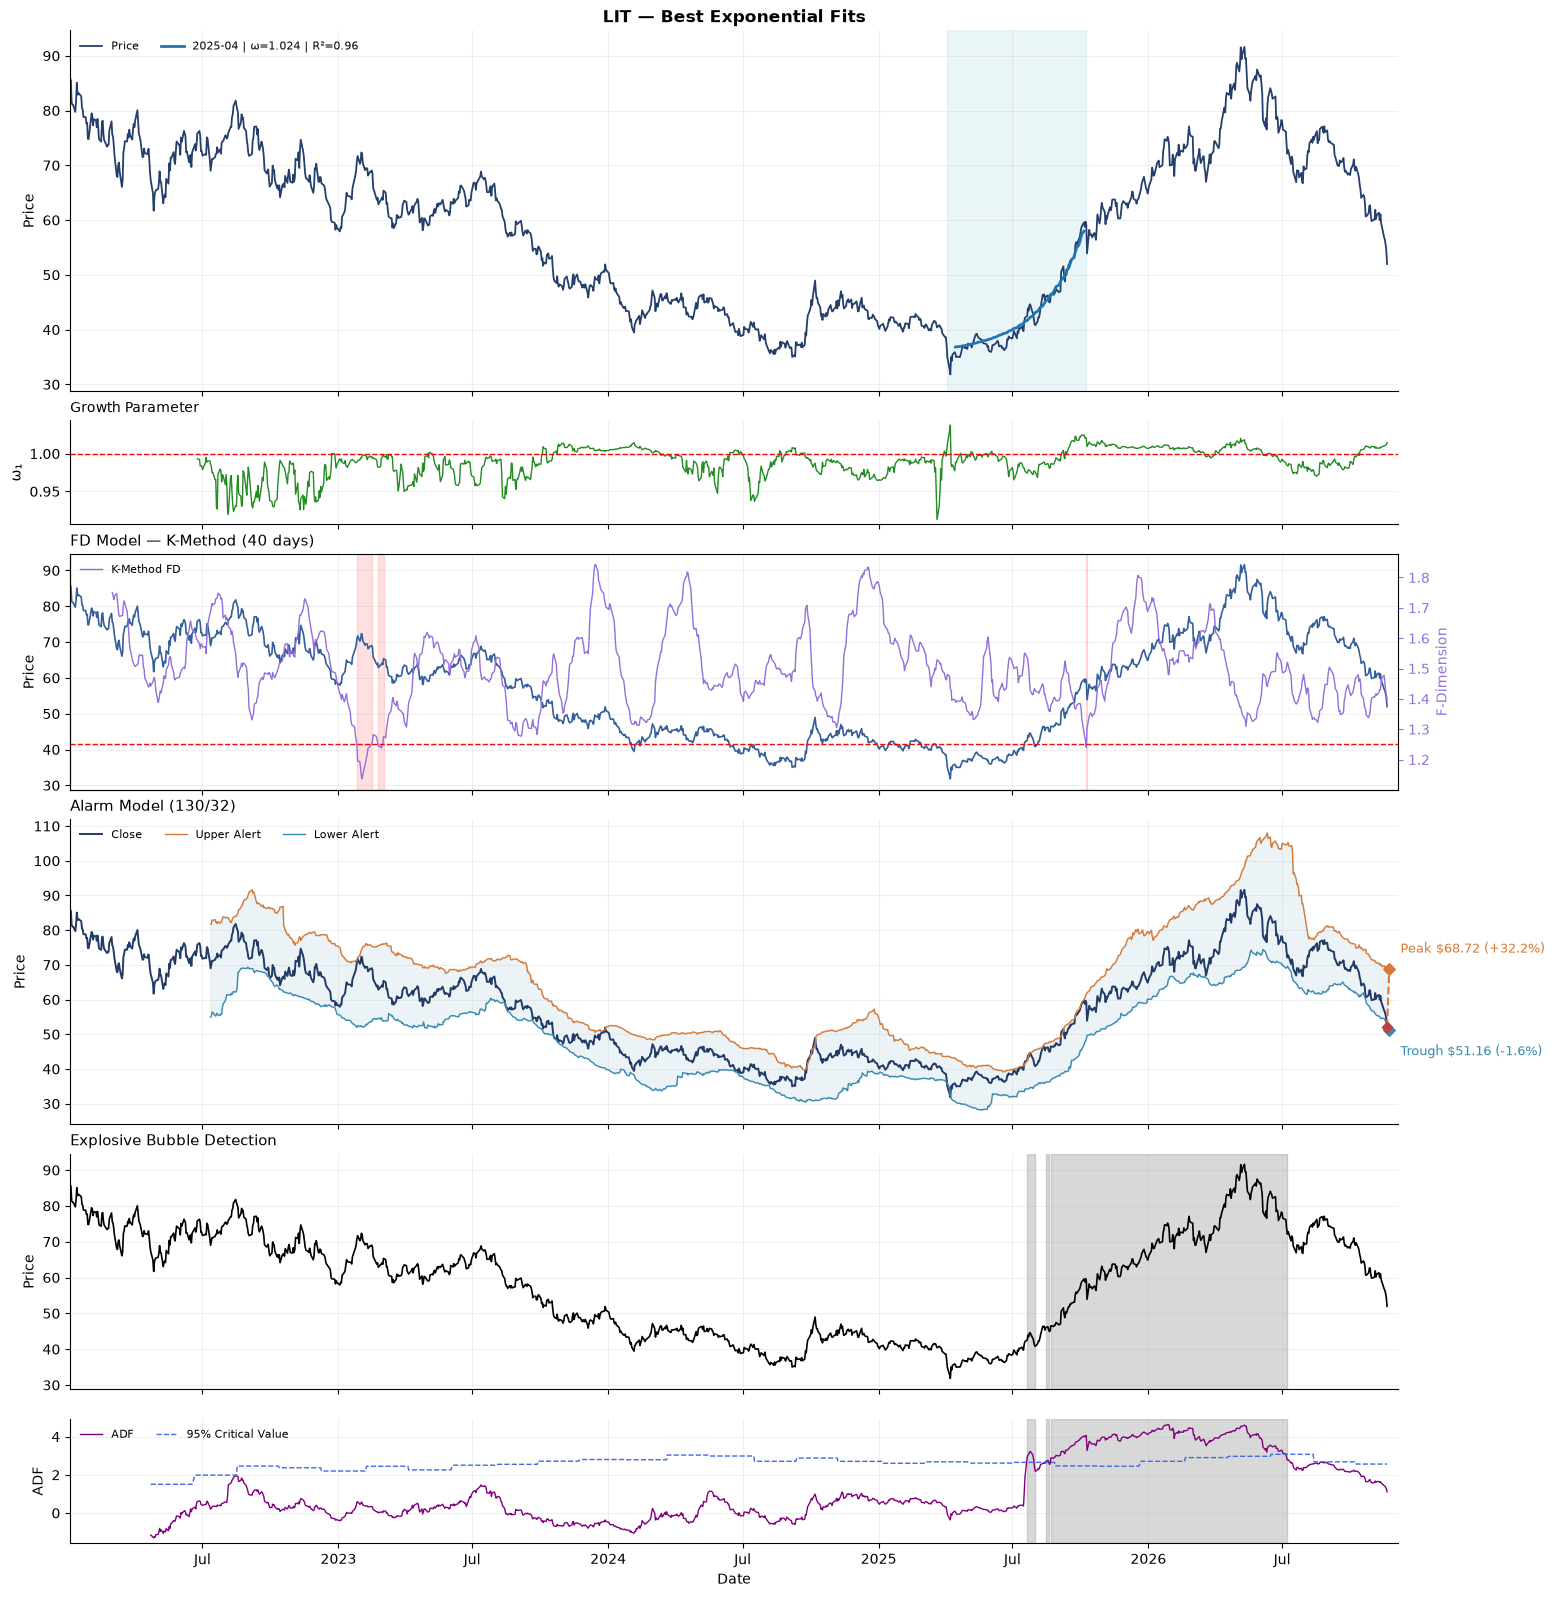


LIT — MODEL SUMMARY
Latest close: 51.98 | Date: 2026-11-20
Exponetial F: 11 bubble windows | 1 fits
FD: 1.397 | Low FD: False
Visibility: Upper 68.72 | Lower 51.16
ADF: 4.640 | Bubble: False


In [3]:

# -*- coding: utf-8 -*-
# Bubble & Market Structure Dashboard
# EXCF + Fractal Dimension + Extreme Visibility + GSADF

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests, math, warnings
from datetime import datetime
from scipy.stats import t as student_t
from numba import njit

warnings.filterwarnings("ignore")

# ================= SETTINGS =================
API_KEY = '490ed0ef6adef36a548539c3e6da425e'
Portfolio = ["SOXX"]
START = "2022-01-01"
END = datetime.today().strftime("%Y-%m-%d")

# EXCF
EXCF_WINDOW = 120
EXCF_ALPHA = 0.05
EXCF_MIN_OBS = 12
EXCF_FREQ = "D"           # "D" or "W-FRI"
EXCF_OVERLAP = 0.6
EXCF_MAX_FITS = 8
EXCF_MIN_R2 = 0.3

# Fractal Dimension
FD_WINDOW = 40
FD_METHOD = "K-Method"       # "Katz" or "Higuchi"
FD_THRESHOLD = 1.25
FD_KMAX = 10

# Extreme Visibility
EV_WINDOW = 130
EV_TARGET = 32
EV_MAX_MULTIPLE = 10

# GSADF
CV_SIMS = 80
CV_EVERY = 40
CV_SEED = 42

# Plot
PLOT_DAYS = None          # None = full history
LOG_PRICE = False
# ============================================


# ============================================================
# 1. ONE DATA DOWNLOAD FUNCTION
# ============================================================

def get_prices(symbol, start=START, end=END, api_key=API_KEY):
    sources = [
        ("Stable", "https://financialmodelingprep.com/stable/historical-price-eod/full",
         {"symbol": symbol, "from": start, "to": end, "apikey": api_key}),
        ("Legacy", f"https://financialmodelingprep.com/api/v3/historical-price-full/{symbol}",
         {"from": start, "to": end, "apikey": api_key})
    ]

    errors = []
    for name, url, params in sources:
        try:
            r = requests.get(url, params=params, timeout=30)
            r.raise_for_status()
            js = r.json()
            data = js if isinstance(js, list) else js.get("historical", [])
            df = pd.DataFrame(data)[["date", "close"]].copy()
            df["date"] = pd.to_datetime(df["date"])
            df["close"] = pd.to_numeric(df["close"], errors="coerce")
            df = (df.dropna().query("close > 0")
                    .drop_duplicates("date").set_index("date")
                    .sort_index().loc[start:end])
            if df.empty: raise ValueError("Empty prices")
            print(f"{symbol}: {len(df)} observations | {name}")
            return df["close"].astype(float)
        except Exception as e:
            errors.append(f"{name}: {e}")

    raise RuntimeError("FMP failed:\n" + "\n".join(errors))


# ============================================================
# 2. EXCF DETECTOR + BEST FITS
# ============================================================

def run_excf(price, window=EXCF_WINDOW):
    px = price.resample(EXCF_FREQ).last().dropna() if EXCF_FREQ != "D" else price
    rows = []
    if len(px) < window: return px, pd.DataFrame(), []

    for end in range(window, len(px)+1):
        w = px.iloc[end-window:end]
        y = w.to_numpy()
        p0 = y[0]
        x, z = y[:-1]-p0, y[1:]-p0

        xx = np.dot(x, x)
        if xx <= 0: continue

        omega = np.dot(x, z)/xx
        residual = z-omega*x
        dof = len(x)-1
        se = np.sqrt(np.dot(residual,residual)/dof/xx) if dof > 0 else np.nan
        pval = 2*student_t.sf(abs((omega-1)/se), dof) if se > 0 else np.nan
        ss = np.sum((z-z.mean())**2)
        r2 = 1-np.dot(residual,residual)/ss if ss > 0 else np.nan
        bubble = bool(omega > 1 and pval < EXCF_ALPHA and r2 > 0.3)

        rows.append(dict(start=w.index[0], end=w.index[-1],
                         omega1=omega, p_val=pval, r_squared=r2,
                         P0=p0, is_bubble=bubble))

    sig = pd.DataFrame(rows)
    candidates = []

    for s in sig.itertuples():
        if not s.is_bubble: continue
        w = px.loc[s.start:s.end]
        y = w.to_numpy()
        t = np.arange(len(y))

        with np.errstate(over="ignore", invalid="ignore"):
            basis = s.omega1**t

        den = np.dot(basis,basis)
        if not np.isfinite(den) or den <= 0: continue

        A = np.dot(basis,y-s.P0)/den
        curve = s.P0+A*basis
        ss = np.sum((y-y.mean())**2)
        r2 = 1-np.sum((y-curve)**2)/ss if ss > 0 else np.nan

        if not np.isfinite(r2) or r2 < EXCF_MIN_R2: continue
        candidates.append(dict(start=s.start,end=s.end,dates=w.index,
                               curve=curve,omega=s.omega1,r2=r2))

    candidates.sort(key=lambda x:x["r2"],reverse=True)
    selected = []

    for c in candidates:
        overlap = any(
            len(c["dates"].intersection(z["dates"])) /
            min(len(c["dates"]),len(z["dates"])) >= EXCF_OVERLAP
            for z in selected
        )
        if not overlap:
            selected.append(c)
        if len(selected) >= EXCF_MAX_FITS: break

    return px, sig, sorted(selected,key=lambda x:x["start"])


# ============================================================
# 3. FRACTAL DIMENSION
# ============================================================

def run_fd(price, window=FD_WINDOW, method=FD_METHOD):

    def katz(x):
        L = np.abs(np.diff(x)).sum()
        d = np.max(np.abs(x-x[0]))
        if L <= 0 or d <= 0: return np.nan
        den = np.log(len(x)-1)+np.log(d/L)
        return np.log(len(x)-1)/den if den > 0 else np.nan

    def higuchi(x):
        n = len(x)
        lengths, scales = [], []
        for k in range(1,min(FD_KMAX,(n-1)//2)+1):
            vals = []
            for m in range(k):
                z = x[m::k]
                steps = len(z)-1
                if steps > 0:
                    vals.append(np.abs(np.diff(z)).sum() *
                                (n-1)/(steps*k*k))
            if vals and np.mean(vals)>0:
                lengths.append(np.mean(vals))
                scales.append(k)
        return (-np.polyfit(np.log(scales),np.log(lengths),1)[0]
                if len(scales)>=3 else np.nan)

    fn = katz if method.lower()=="katz" else higuchi
    fd = price.rolling(window).apply(fn,raw=True)
    return pd.DataFrame({"Price":price,"FD":fd,
                         "Low_FD":fd.lt(FD_THRESHOLD)&fd.notna()})


# ============================================================
# 4. EXTREME VISIBILITY CORRIDOR
# ============================================================

def visibility_thresholds(logs, window=EV_WINDOW, target=EV_TARGET):
    n = len(logs)
    if n < window or target < 1 or target > window:
        return np.nan,np.nan

    peaks, troughs = np.empty(window),np.empty(window)
    for pos,i in enumerate(range(n-window,n)):
        if i==n-1:
            peaks[pos],troughs[pos] = -np.inf,np.inf
            continue
        k = np.arange(i+1,n)
        v = logs[i]+(n-i)*(logs[k]-logs[i])/(k-i)
        peaks[pos],troughs[pos] = v.max(),v.min()

    base = np.exp(logs[-1])
    upper = np.exp(max(logs[-1],np.partition(peaks,target-1)[target-1]))
    lower = np.exp(min(logs[-1],np.partition(troughs,window-target)[window-target]))

    if not np.isfinite(upper) or upper>base*EV_MAX_MULTIPLE:
        upper=np.nan
    if not np.isfinite(lower) or lower<base/EV_MAX_MULTIPLE:
        lower=np.nan
    return upper,lower


def run_visibility(price):
    logs = np.log(price.to_numpy())
    n = len(price)
    upper,lower = np.full(n,np.nan),np.full(n,np.nan)

    for j in range(EV_WINDOW,n):
        upper[j],lower[j] = visibility_thresholds(logs[:j])

    next_up,next_dn = visibility_thresholds(logs)
    return pd.DataFrame({"Price":price,"Upper":upper,"Lower":lower}),next_up,next_dn


# ============================================================
# 5. GSADF — NUMBA ACCELERATED
# ============================================================

@njit
def _cross_prefix(y):
    T=len(y)
    maxlag=int(1.5*T**(1/3))+1
    p=maxlag+2
    S=np.zeros((T+1,p,p))
    z=np.zeros(p)

    for t in range(T):
        z[:]=0.0
        z[0]=y[t]
        for j in range(1,maxlag+1):
            if t>=j: z[j]=y[t-j+1]-y[t-j]
        if t<T-1: z[-1]=y[t+1]-y[t]
        for i in range(p):
            for j in range(p):
                S[t+1,i,j]=S[t,i,j]+z[i]*z[j]
    return S


@njit
def _adf_fast(S,r1,r2):
    n=r2-r1+1
    k=int(1.5*n**(1/3))
    rows=n-1-k
    p=k+1
    if rows<=p or p>=S.shape[1]: return -1e9

    low,high,target=r1+k,r2,S.shape[1]-1
    xx=np.empty((p,p))
    xy=np.empty(p)

    for i in range(p):
        xy[i]=S[high,i,target]-S[low,i,target]
        for j in range(p):
            xx[i,j]=S[high,i,j]-S[low,i,j]

    yy=S[high,target,target]-S[low,target,target]
    try:
        beta=np.linalg.solve(xx,xy)
        e0=np.zeros(p); e0[0]=1.
        inv00=np.linalg.solve(xx,e0)[0]
    except:
        return -1e9

    var=(yy-np.dot(beta,xy))/(rows-p)*inv00
    if var<=0 or not np.isfinite(var): return -1e9
    return beta[0]/np.sqrt(var)


@njit
def rolling_bsadf(logp,min_win):
    T=len(logp)
    out=np.full(T,np.nan)
    S=_cross_prefix(logp)

    for r2 in range(min_win,T):
        mx=-1e9
        for r1 in range(r2-min_win+1):
            v=_adf_fast(S,r1,r2)
            if v>mx: mx=v
        out[r2]=mx
    return out


@njit
def _cv_paths(paths,min_win,endpoints):
    B=paths.shape[0]
    out=np.empty((B,len(endpoints)))

    for b in range(B):
        S=_cross_prefix(paths[b])
        for j in range(len(endpoints)):
            r2=endpoints[j]
            mx=-1e9
            for r1 in range(r2-min_win+1):
                v=_adf_fast(S,r1,r2)
                if v>mx: mx=v
            out[b,j]=mx
    return out


def run_gsadf(price):
    logp=np.log(price.to_numpy())
    T=len(logp)
    min_win=math.ceil((0.01+1.8/np.sqrt(T))*T)
    if T<=min_win: raise ValueError("Insufficient GSADF observations")

    bsadf=rolling_bsadf(logp,min_win)

    sigma=np.std(np.diff(logp[:min_win+1]),ddof=1)
    if not np.isfinite(sigma) or sigma<=0:
        raise ValueError("Invalid initial volatility")

    endpoints=np.arange(min_win,T,CV_EVERY,dtype=np.int64)
    rng=np.random.default_rng(CV_SEED)
    paths=np.empty((CV_SIMS,T))
    paths[:,0]=logp[0]
    paths[:,1:]=logp[0]+np.cumsum(
        rng.normal(0,sigma,(CV_SIMS,T-1)),axis=1
    )

    q=np.quantile(_cv_paths(paths,min_win,endpoints),0.95,axis=0)
    cv=np.full(T,np.nan)
    for j,r2 in enumerate(endpoints):
        nxt=endpoints[j+1] if j+1<len(endpoints) else T
        cv[r2:nxt]=q[j]

    return pd.DataFrame({"Price":price,"BSADF":bsadf,
                         "CV95":cv,"Bubble":bsadf>cv})


# ============================================================
# 6. SHARED INTERVAL HELPER
# ============================================================

def periods_from_flags(dates,flags):
    periods=[]
    start=None
    for d,f in zip(dates,flags):
        if f and start is None: start=d
        elif not f and start is not None:
            periods.append((start,d))
            start=None
    if start is not None: periods.append((start,dates[-1]))
    return periods


# ============================================================
# 7. UNIFIED DASHBOARD
# ============================================================

def bubble_dashboard(symbol,start=START,end=END,api_key=API_KEY):
    price=get_prices(symbol,start,end,api_key)
    if len(price)<max(EXCF_WINDOW,EV_WINDOW,FD_WINDOW)+2:
        raise ValueError("Insufficient observations for selected windows")

    excf_px,excf,fits=run_excf(price)
    fd=run_fd(price)
    ev,next_up,next_dn=run_visibility(price)
    gs=run_gsadf(price)

    fig,axes=plt.subplots(
        6,1,figsize=(16,17),sharex=True,
        gridspec_kw={"height_ratios":[2.6,0.75,1.7,2.2,1.7,0.9],
                     "hspace":0.13}
    )
    ax1,ax2,ax3,ax4,ax5,ax6=axes
    def disp(x):
        return np.log(np.where(np.asarray(x)>0,x,np.nan)) if LOG_PRICE else x

    # ---------- 1 EXCF BEST FIT ----------
    ax1.plot(price.index,disp(price),color="#243f6b",lw=1.3,label="Price")

    if not excf.empty:
        # Same bubble-window shading as original third panel
        intervals=sorted(zip(excf.loc[excf.is_bubble,"start"],
                             excf.loc[excf.is_bubble,"end"]))
        merged=[]
        for a,b in intervals:
            if merged and a<=merged[-1][1]:
                merged[-1]=(merged[-1][0],max(b,merged[-1][1]))
            else:
                merged.append((a,b))
        for a,b in merged:
            ax1.axvspan(a,b,color="lightblue",alpha=.25,zorder=0)

        omega=excf.set_index("end")["omega1"]
        ax2.plot(omega.index,omega,color="forestgreen",lw=1)

    colors=plt.cm.tab10(np.linspace(0,1,max(len(fits),1)))
    for i,f in enumerate(fits):
        ax1.plot(f["dates"],disp(f["curve"]),color=colors[i],lw=2,
                 label=f'{f["start"]:%Y-%m} | ω={f["omega"]:.3f} | R²={f["r2"]:.2f}')

    ax1.set_title(f"{symbol} — Best Exponential Fits",fontweight="bold")
    ax1.set_ylabel("Log Price" if LOG_PRICE else "Price")
    ax1.legend(loc="upper left",fontsize=8,ncol=2,frameon=False)

    # ---------- 2 OMEGA ----------
    ax2.axhline(1,color="red",ls="--",lw=1)
    ax2.set_ylabel("ω₁")
    ax2.set_title("Growth Parameter",fontsize=10,loc="left")

    # ---------- 3 FRACTAL DIMENSION ----------
    ax3.plot(price.index,disp(price),color="#345f9b",lw=1.2)
    ax3r=ax3.twinx()
    ax3r.plot(fd.index,fd.FD,color="mediumpurple",lw=1,
              label=f"{FD_METHOD} FD")
    ax3r.axhline(FD_THRESHOLD,color="red",ls="--",lw=1)
    ax3r.set_ylabel("F-Dimension",color="mediumpurple")
    ax3r.tick_params(axis="y",colors="mediumpurple")

    for s,e in periods_from_flags(fd.index,fd.Low_FD):
        ax3.axvspan(s,e,color="red",alpha=.12)

    ax3.set_title(f"FD Model — {FD_METHOD} ({FD_WINDOW} days)",
                  fontsize=11,loc="left")
    ax3.set_ylabel("Price")
    ax3r.legend(loc="upper left",fontsize=8,frameon=False)

    # ---------- 4 EXTREME VISIBILITY ----------
    ax4.plot(ev.index,ev.Price,color="#223b66",lw=1.4,label="Close")
    ax4.plot(ev.index,ev.Upper,color="#d57935",lw=1,label="Upper Alert")
    ax4.plot(ev.index,ev.Lower,color="#398ab1",lw=1,label="Lower Alert")
    ax4.fill_between(ev.index,ev.Lower.to_numpy(),ev.Upper.to_numpy(),
                     color="#a8c9dd",alpha=.22)

    last_date=price.index[-1]
    last_close=price.iloc[-1]
    next_date=last_date+pd.offsets.BDay(1)

    for level,color,label,offset in [
        (next_up,"#d57935","Peak",12),
        (next_dn,"#398ab1","Trough",-18)
    ]:
        if np.isfinite(level):
            ax4.plot([last_date,next_date],[last_close,level],
                     "--",color=color,lw=1.5)
            ax4.scatter(next_date,level,marker="D",color=color,s=35,zorder=5)
            pct=(level/last_close-1)*100
            ax4.annotate(f"{label} ${level:,.2f} ({pct:+.1f}%)",
                         xy=(next_date,level),xytext=(8,offset),
                         textcoords="offset points",color=color,fontsize=9)

    ax4.scatter(last_date,last_close,marker="D",color="#bb4141",s=28,zorder=6)
    ax4.set_title(f"Alarm Model ({EV_WINDOW}/{EV_TARGET})",
                  fontsize=11,loc="left")
    ax4.set_ylabel("Price")
    ax4.legend(loc="upper left",ncol=3,fontsize=8,frameon=False)

    # ---------- 5 GSADF PRICE ----------
    ax5.plot(price.index,disp(price),color="black",lw=1.2,label="Price")
    gs_periods=periods_from_flags(gs.index,gs.Bubble)

    for s,e in gs_periods:
        ax5.axvspan(s,e,color="gray",alpha=.30)
        ax6.axvspan(s,e,color="gray",alpha=.30)

    ax5.set_title("Explosive Bubble Detection",
                  fontsize=11,loc="left")
    ax5.set_ylabel("Price")

    # ---------- 6 BSADF + CV ----------
    ax6.plot(gs.index,gs.BSADF,color="purple",lw=1,label="ADF")
    ax6.plot(gs.index,gs.CV95,color="royalblue",ls="--",
             lw=1,label="95% Critical Value")
    ax6.set_ylabel("ADF")
    ax6.legend(loc="upper left",fontsize=8,ncol=2,frameon=False)

    # ---------- COMMON X AXIS ----------
    for ax in axes:
        ax.grid(alpha=.18)
        ax.spines[["top","right"]].set_visible(False)
        ax.tick_params(axis="x",which="both",labelbottom=False)
        ax.margins(x=0)

    locator=mdates.AutoDateLocator(minticks=5,maxticks=12)
    ax6.xaxis.set_major_locator(locator)
    ax6.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax6.tick_params(axis="x",labelbottom=True)
    ax6.set_xlabel("Date")

    left = (price.index[-1]-pd.Timedelta(days=PLOT_DAYS)
            if PLOT_DAYS is not None else price.index[0])
    right=next_date+pd.Timedelta(days=12)
    ax6.set_xlim(left,right)

    # Manually align all six plotting areas.
    fig.subplots_adjust(left=.08,right=.91,top=.95,bottom=.06,hspace=.25)
    plt.show()

    print(f"\n{'='*55}\n{symbol} — MODEL SUMMARY")
    print(f"Latest close: {last_close:.2f} | Date: {last_date.date()}")
    print(f"Exponetial F: {int(excf.is_bubble.sum()) if not excf.empty else 0} bubble windows | {len(fits)} fits")
    print(f"FD: {fd.FD.iloc[-1]:.3f} | Low FD: {bool(fd.Low_FD.iloc[-1])}")
    print(f"Visibility: Upper {next_up:.2f} | Lower {next_dn:.2f}")
    print(f"ADF: {np.nanmax(gs.BSADF):.3f} | Bubble: {bool(gs.Bubble.iloc[-1])}")
    print("="*55)

    return {"price":price,"EXCF":excf,"fits":fits,
            "FD":fd,"Visibility":ev,"GSADF":gs}


# ============================================================
# 8. RUN — ONE SYMBOL, ONE START DATE
# ============================================================
Portfolio = ["LIT"]
START = "2022-01-01"
for Symbol in Portfolio:
    result=bubble_dashboard(Symbol,START,END,API_KEY)
